# Iris Flower Classification
## Exploratory Data Analysis (EDA)

### 1. Notebook Overview

This notebook focuses on the exploratory data analysis (EDA) of the Iris flower dataset, a well-known dataset in machine learning.

The dataset contains measurements of three Iris flower species:
- Setosa
- Versicolor
- Virginica

Each observation includes four numerical features:
- Sepal Length
- Sepal Width
- Petal Length
- Petal Width

### Objectives

The main objectives of this notebook are:

1. Understand the structure and characteristics of the dataset.
2. Identify missing values, duplicated records, and potential data quality issues.
3. Explore the statistical distribution of the numerical features.
4. Visualize relationships between flower measurements.
5. Identify patterns and differences between the three species.
6. Prepare the dataset for the machine learning classification stage.

### Expected Outcome

By the end of this notebook, we aim to understand which flower measurements are most useful for distinguishing the three Iris species and prepare the data for classification.

## 2. Data Loading and Libraries Import

### Objective

This section prepares the analysis environment by importing the required Python libraries and loading the Iris dataset.

We use:
- Pandas for data manipulation and exploration.
- NumPy for numerical operations.
- Matplotlib and Seaborn for data visualization.

The dataset is loaded from the local CSV file stored in the `data` directory.

### Step 2.1 — Importing Libraries and Loading the Dataset

The following code imports the required libraries and reads the CSV file into a Pandas DataFrame.

We then display the first five rows to verify that the dataset has been loaded correctly.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visualization style
sns.set_theme(style="whitegrid")

# Load the dataset
df = pd.read_csv("../data/Iris.csv")

# Display the first five rows
df.head()


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


## 3. Initial Dataset Exploration

### Objective

In this section, we perform an initial exploration of the dataset to understand its structure, dimensions, column names, and data types.

This step helps us determine how many observations and features are available and identify the variables that will be used in the classification task.

### Step 3.1 — Dataset Structure

We use several Pandas methods to inspect the dataset:

- `shape`: returns the number of rows and columns.
- `columns`: displays all column names.
- `info()`: provides information about data types and non-null values.
- `dtypes`: identifies the data type of each column.

In [2]:
# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset information:")
df.info()

# Display data types
print("\nData types:")
print(df.dtypes)

Dataset shape: (150, 6)

Column names:
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB

Data types:
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object


## 4. Data Quality Assessment

### Objective

This section evaluates the quality and consistency of the dataset before performing further analysis.

We investigate:
- Missing values in each column.
- Duplicate records in the dataset.
- The distribution of observations across the three Iris species.

These checks help identify potential data quality issues that could affect the reliability of the classification model.

### Step 4.1 — Checking Missing Values, Duplicates and Class Distribution

We use the following Pandas methods:

- `isnull().sum()`: counts missing values in each column.
- `duplicated().sum()`: counts duplicated rows.
- `value_counts()`: counts the observations belonging to each species.

We also check whether the `Id` column contains duplicated identifiers.

In [3]:
# 1. Check missing values
print("Missing values per column:")
print(df.isnull().sum())

# 2. Check duplicated rows
print("\nNumber of duplicated rows:")
print(df.duplicated().sum())

# 3. Check duplicated IDs
print("\nNumber of duplicated IDs:")
print(df["Id"].duplicated().sum())

# 4. Check species distribution
print("\nSpecies distribution:")
print(df["Species"].value_counts())

Missing values per column:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Number of duplicated rows:
0

Number of duplicated IDs:
0

Species distribution:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


### Step 4.2 — Data Quality Assessment Results

The dataset quality assessment produced the following results:

- No missing values were found.
- No duplicated records were detected.
- All flower IDs are unique.
- Each Iris species contains exactly 50 observations.

The dataset is therefore balanced, with 150 observations distributed equally among the three classes.

### Conclusion

No missing-value imputation or duplicate removal is required at this stage.

The dataset is suitable for further exploratory analysis. However, potential outliers and unusual feature distributions will be investigated in the following sections.

## 5. Descriptive Statistical Analysis

### Objective

This section explores the statistical characteristics of the numerical features in the Iris dataset.

We calculate descriptive statistics to understand the central tendency, variability, and range of flower measurements.

This analysis helps us identify differences in measurement scales and understand how the numerical features are distributed.

### Step 5.1 — Computing Descriptive Statistics

We use the Pandas `describe()` method to calculate:

- Count: number of observations.
- Mean: average value.
- Std: standard deviation, which measures variability.
- Min: minimum value.
- 25%: first quartile.
- 50%: median.
- 75%: third quartile.
- Max: maximum value.

The ID column is excluded because it is an identifier rather than a meaningful biological measurement.

In [4]:
# Select numerical flower measurements
numerical_features = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

# Generate descriptive statistics
df[numerical_features].describe()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### Step 5.2 — Descriptive Statistics by Species

### Objective

In this section, we compare the statistical characteristics of the four numerical features across the three Iris species.

The purpose is to identify differences in flower measurements between Setosa, Versicolor, and Virginica.

This analysis helps us understand which features may be useful for distinguishing the species during the classification task.

We use the Pandas `groupby()` method to divide the dataset into groups based on the `Species` column.

For each species, we calculate:
- Mean: average measurement.
- Standard deviation: variability of measurements.
- Minimum: smallest observed measurement.
- Maximum: largest observed measurement.

This allows us to compare the characteristics of the three species.

In [5]:
# Calculate descriptive statistics for each species
species_statistics = df.groupby("Species")[numerical_features].agg(
    ["mean", "std", "min", "max"]
)

species_statistics

SepalLengthCm                     SepalWidthCm                 \
                         mean       std  min  max         mean       std  min   
Species                                                                         
Iris-setosa             5.006  0.352490  4.3  5.8        3.418  0.381024  2.3   
Iris-versicolor         5.936  0.516171  4.9  7.0        2.770  0.313798  2.0   
Iris-virginica          6.588  0.635880  4.9  7.9        2.974  0.322497  2.2   

                     PetalLengthCm                     PetalWidthCm            \
                 max          mean       std  min  max         mean       std   
Species                                                                         
Iris-setosa      4.4         1.464  0.173511  1.0  1.9        0.244  0.107210   
Iris-versicolor  3.4         4.260  0.469911  3.0  5.1        1.326  0.197753   
Iris-virginica   3.8         5.552  0.551895  4.5  6.9        2.026  0.274650   

                           
                 min  max  
Species                    
Iris-setosa      0.1  0.6  
Iris-versicolor  1.0  1.8  
Iris-virginica   1.4  2.5

### Step 5.3 — Statistical Findings

The comparison of descriptive statistics across species reveals several interesting patterns:

- Setosa has the smallest average petal length and petal width.
- Virginica has the largest average petal length and petal width.
- Versicolor generally presents intermediate petal measurements.
- Sepal width shows less separation between Versicolor and Virginica.
- Sepal length also varies across species, although the ranges overlap.

### Preliminary Conclusion

Petal length and petal width appear to be promising features for distinguishing Iris species.

However, these observations are based on summary statistics. Further visual analysis is required to examine the distributions and overlap between species before drawing definitive conclusions about feature importance.

## 6. Exploratory Data Visualization

### Objective

This section uses graphical representations to better understand the distribution of the numerical features and their differences across Iris species.

Visualizations help identify patterns, overlaps, and potential relationships that may not be obvious from descriptive statistics alone.

### Step 6.1 — Feature Distribution Histograms

Histograms are used to visualize the distribution of numerical measurements.

We create one histogram for each numerical feature and use different colors to represent the three Iris species.

This allows us to compare the distributions of Setosa, Versicolor, and Virginica and identify which measurements provide the clearest separation between classes.

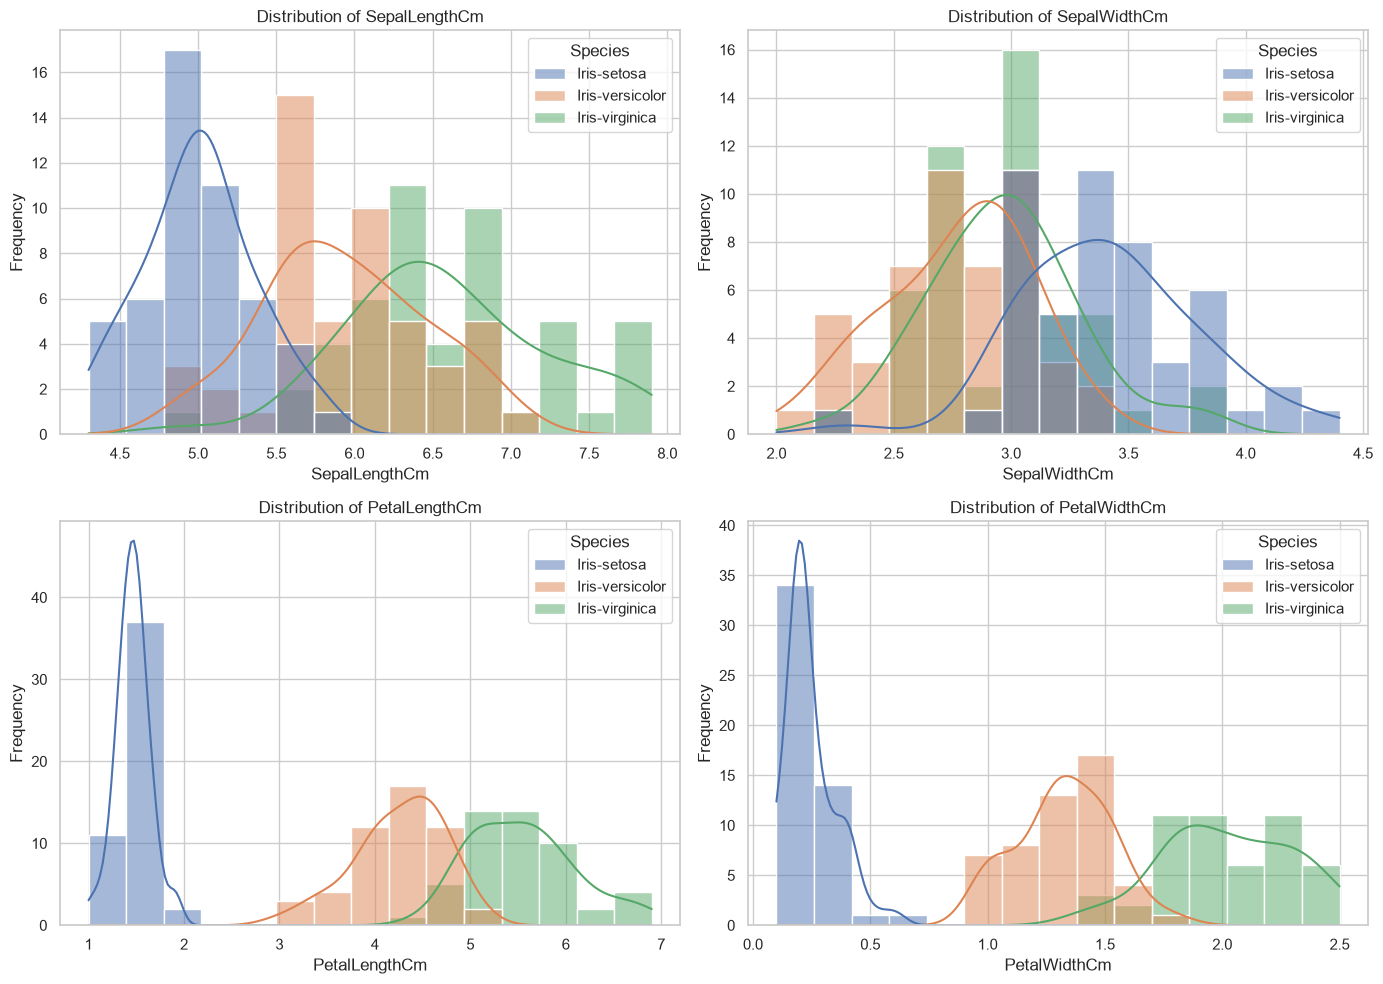

In [6]:
# Create a 2x2 grid of histograms
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Flatten the axes array for easier iteration
axes = axes.flatten()

# Plot the distribution of each numerical feature
for i, feature in enumerate(numerical_features):
    sns.histplot(
        data=df,
        x=feature,
        hue="Species",
        kde=True,
        bins=15,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Frequency")

# Adjust layout
plt.tight_layout()
plt.show()

### Step 6.2 — Histogram Analysis and Key Findings

The histograms reveal several differences in the distributions of the four numerical features across Iris species.

**Sepal Length:**
- The three species show different central distributions.
- Some overlap exists, particularly between Versicolor and Virginica.

**Sepal Width:**
- The distributions overlap considerably.
- This feature appears less discriminative when considered individually.

**Petal Length:**
- Setosa is clearly separated from the other two species.
- Some overlap exists between Versicolor and Virginica.

**Petal Width:**
- Setosa shows distinctly smaller values.
- Versicolor and Virginica are also relatively well separated, with partial overlap.

### Overall Conclusion

Petal length and petal width appear to provide stronger visual separation between the three Iris species than sepal measurements.

These findings suggest that petal measurements may be particularly useful for the classification task.

Further analysis is required before determining the final contribution of each feature to model performance.

### Step 6.3 — Boxplot Analysis and Outlier Detection

### Objective

In this section, we use boxplots to compare the distributions of numerical features across Iris species.

Boxplots provide information about the median, quartiles, variability, and potential outliers.

This analysis helps identify unusual observations and better understand the spread of each feature within each species.

We create one boxplot for each numerical feature.

The `x` parameter represents the Iris species, while the `y` parameter represents the numerical measurement.

We use the `showfliers=True` option to display potential outliers.

Potential outliers will be investigated rather than automatically removed.

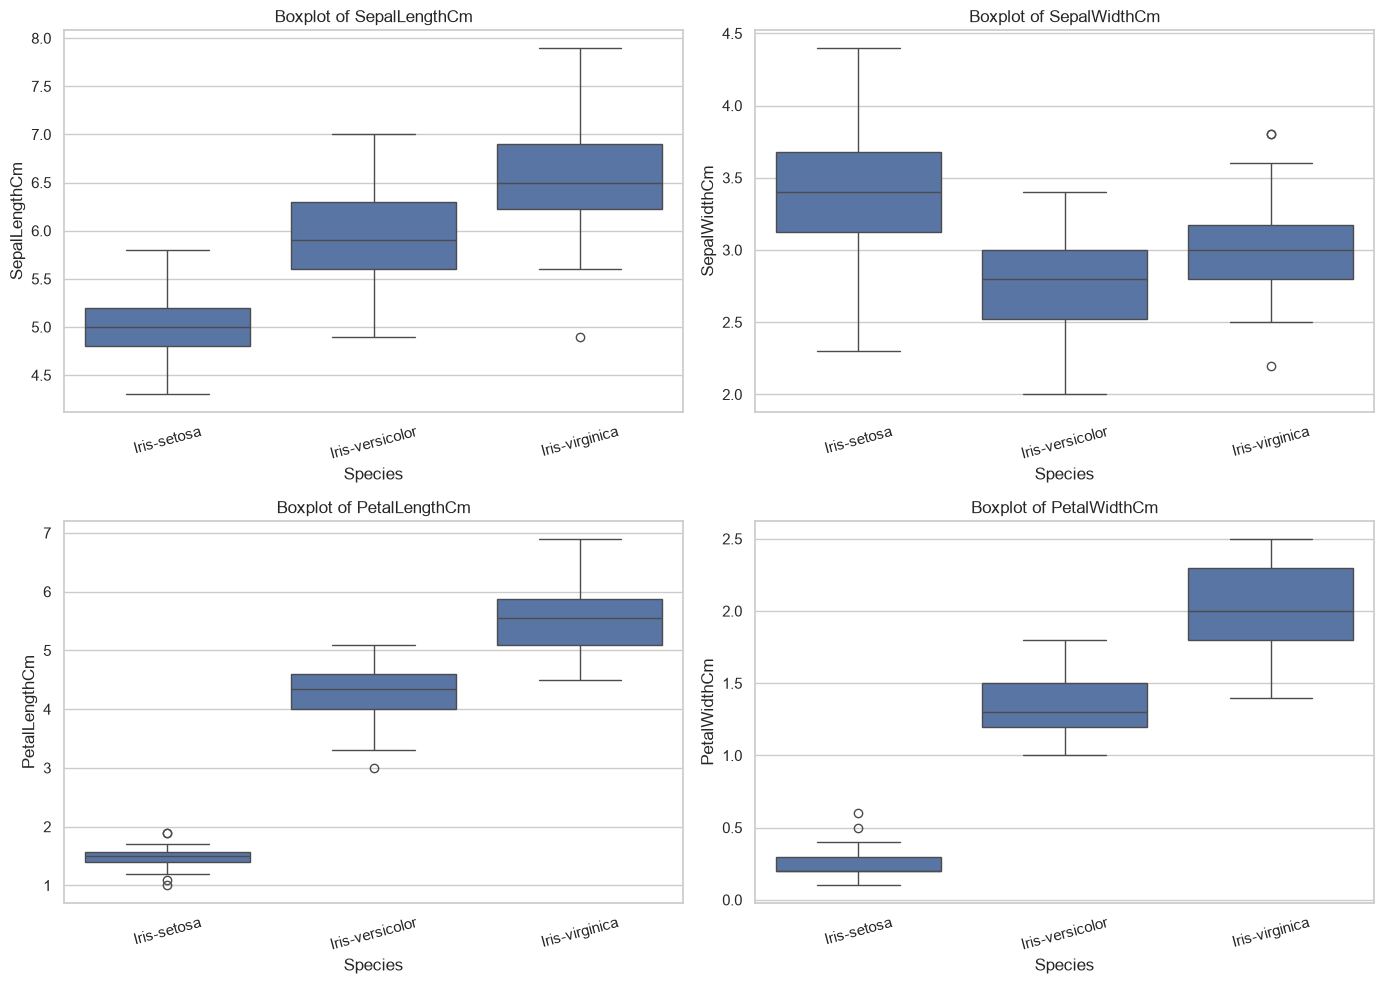

In [7]:
# Create a 2x2 grid of boxplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes = axes.flatten()

# Generate one boxplot for each feature
for i, feature in enumerate(numerical_features):
    sns.boxplot(
        data=df,
        x="Species",
        y=feature,
        ax=axes[i],
        showfliers=True
    )

    axes[i].set_title(f"Boxplot of {feature}")
    axes[i].set_xlabel("Species")
    axes[i].set_ylabel(feature)
    axes[i].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

### Step 6.4 — Boxplot Analysis and Outlier Observations

The boxplots provide additional insights into the distributions of the numerical features across the three Iris species.

Key observations:

- Sepal length shows differences in median values across species, with some overlap.
- Sepal width presents considerable overlap, particularly between Versicolor and Virginica.
- Petal length shows strong separation between Setosa, Versicolor, and Virginica.
- Petal width also provides clear differences between the three species.

Potential outliers were identified in some feature distributions, particularly for petal measurements and sepal width.

### Outlier Handling Decision

Potential outliers are not necessarily data errors. They may represent natural biological variation.

Therefore, no observations will be removed at this stage. Further investigation would be required before modifying the dataset.

### Conclusion

The boxplot analysis supports the preliminary finding that petal length and petal width are particularly informative features for distinguishing Iris species.

## 7. Feature Relationship and Correlation Analysis

### Objective

This section investigates the relationships between numerical features using correlation analysis.

We calculate Pearson correlation coefficients to identify positive and negative linear relationships between flower measurements.

This analysis helps us understand how features are related and whether some measurements provide similar information.

### Step 7.1 — Computing the Correlation Matrix

We use the Pandas `corr()` method to calculate the Pearson correlation coefficients between numerical features.

The resulting correlation matrix measures the strength and direction of linear relationships between each pair of features.

The `Id` column is excluded because it is only an identifier and has no biological meaning.

In [8]:
# Calculate the Pearson correlation matrix
correlation_matrix = df[numerical_features].corr()

# Display the correlation matrix
correlation_matrix

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
SepalLengthCm,1.000000,-0.109369,0.871754,0.817954
SepalWidthCm,-0.109369,1.000000,-0.420516,-0.356544
PetalLengthCm,0.871754,-0.420516,1.000000,0.962757
PetalWidthCm,0.817954,-0.356544,0.962757,1.000000


### Step 7.2 — Correlation Analysis Findings

The Pearson correlation matrix reveals several relationships between the numerical features.

Key findings:

- Petal length and petal width have a very strong positive correlation (0.963).
- Sepal length is strongly positively correlated with petal length (0.872).
- Sepal length is also strongly positively correlated with petal width (0.818).
- Sepal width has moderate negative correlations with petal length (-0.421) and petal width (-0.357).
- Sepal length and sepal width show a very weak negative correlation (-0.109).

### Conclusion

Petal length and petal width tend to increase together, suggesting that they provide related information.

However, correlation alone does not determine whether a feature should be removed from a classification model.

All four numerical features will be retained for further analysis and model evaluation.

### Step 7.3 — Correlation Heatmap

### Objective

This section visualizes the Pearson correlation matrix using a heatmap.

The heatmap provides a graphical representation of the strength and direction of relationships between numerical features.

It makes it easier to identify strongly correlated variables and interpret the overall correlation structure.

We use Seaborn's `heatmap()` function to visualize the correlation matrix.

- `annot=True` displays the correlation values inside each cell.
- `cmap="coolwarm"` uses contrasting colors to represent negative and positive correlations.
- `fmt=".2f"` formats the values to two decimal places.
- `vmin=-1` and `vmax=1` define the correlation scale.

The diagonal values are equal to 1 because each feature is perfectly correlated with itself.

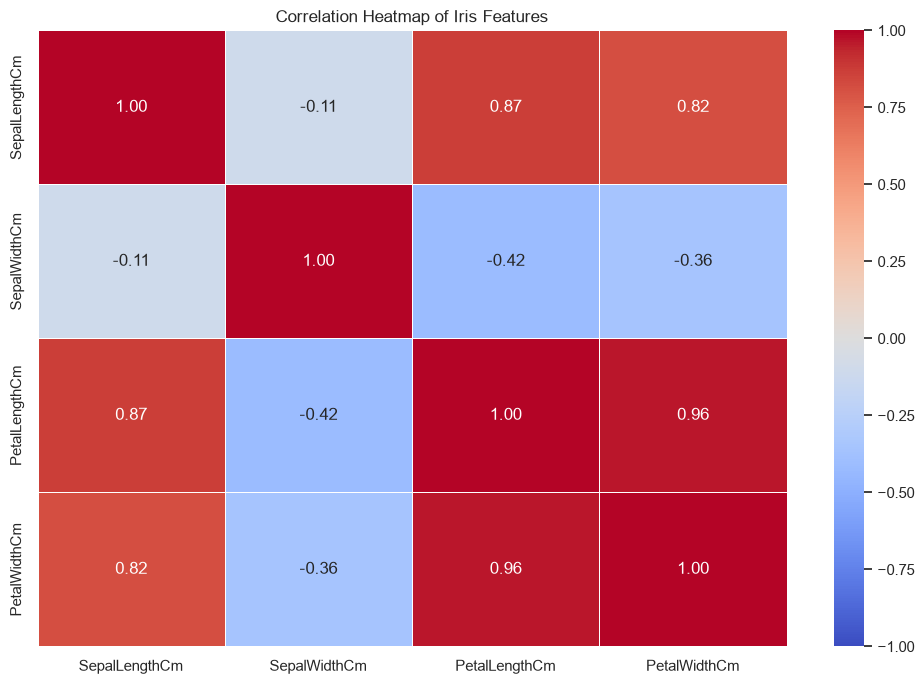

In [9]:
# Create the correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Iris Features")
plt.tight_layout()
plt.show()

### Step 7.4 — Heatmap Interpretation

The correlation heatmap provides a visual summary of the relationships between the numerical features.

Key observations:

- Petal length and petal width exhibit a very strong positive correlation (0.96).
- Sepal length has strong positive correlations with petal length (0.87) and petal width (0.82).
- Sepal width shows negative correlations with petal length (-0.42) and petal width (-0.36).
- Sepal length and sepal width have a very weak negative correlation (-0.11).

### Conclusion

The heatmap confirms that petal measurements are strongly related.

Although some features contain overlapping information, all four measurements will be retained for the classification stage.

Their actual contribution will be assessed through machine learning model evaluation.

## 8. Pairwise Feature Relationship Analysis

### Objective

This section uses a pairplot to visualize pairwise relationships between numerical features.

The plots compare each pair of features and use different colors to represent the three Iris species.

The objective is to identify visual patterns, clusters, and class separation that may help distinguish the species.

### Step 8.1 — Generating the Pairplot

We use Seaborn's `pairplot()` function to generate a collection of plots.

- Each off-diagonal plot shows the relationship between two numerical features.
- The diagonal plots show the distribution of each individual feature.
- The `hue="Species"` parameter assigns a different color to each species.

This visualization helps us understand how well the three species can be separated using combinations of numerical features.

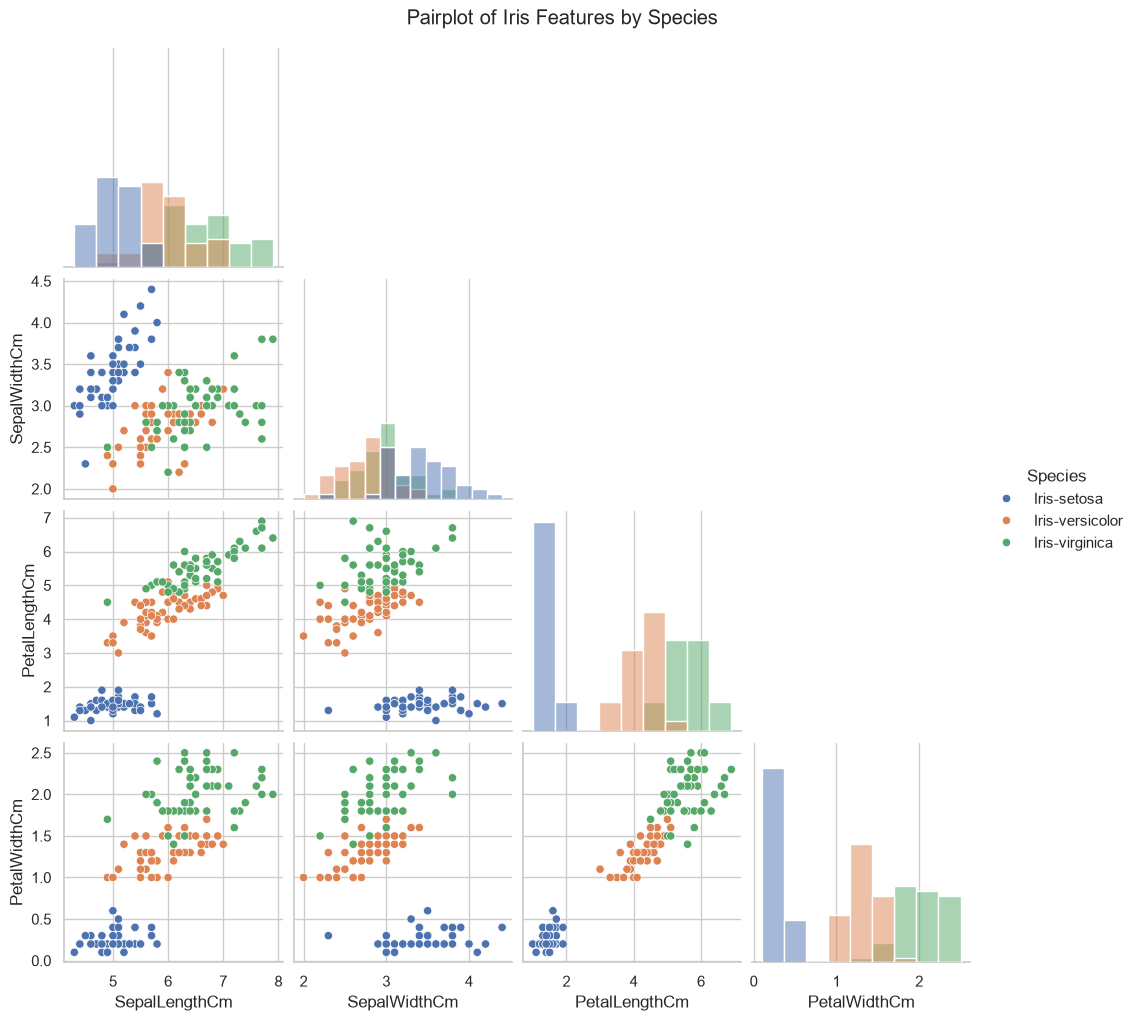

In [10]:
# Generate pairwise feature relationship plots
sns.pairplot(
    data=df,
    vars=numerical_features,
    hue="Species",
    diag_kind="hist",
    corner=True,
    height=2.5
)

plt.suptitle(
    "Pairplot of Iris Features by Species",
    y=1.02
)

plt.show()

### Step 8.2 — Pairplot Analysis and Key Findings

The pairplot provides a comprehensive visualization of pairwise relationships between the four numerical features.

Key observations:

- Iris-setosa forms clearly separated clusters, especially when petal measurements are considered.
- Iris-versicolor and Iris-virginica show some overlap, making their classification more challenging.
- Petal length and petal width provide strong visual separation between species.
- The positive relationship between petal length and petal width confirms the correlation analysis.
- Sepal measurements provide additional information, although their individual separation power appears more limited.

### Conclusion

The pairplot confirms that petal measurements are particularly informative for distinguishing Iris species.

Setosa appears visually easy to separate, while Versicolor and Virginica require more detailed classification.

All four numerical features will be retained for the machine learning stage.

## 9. Exploratory Data Analysis — Final Summary

### Objective

This section summarizes the main findings from the exploratory data analysis.

It consolidates the results obtained from dataset exploration, data quality assessment, descriptive statistics, distribution analysis, boxplots, correlation analysis, and pairwise visualizations.

The findings will guide the data preprocessing and machine learning stages.

### Step 9.1 — Summary of EDA Findings

The final EDA summary focuses on:

- Dataset structure and quality.
- Class distribution.
- Most informative numerical features.
- Relationships between features.
- Potential outliers.
- Observations relevant to model development.

These findings will be used to justify preprocessing decisions and prepare the classification dataset.

In [11]:
# Dataset overview
print("DATASET OVERVIEW")
print("----------------")
print(f"Number of observations: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")
print(f"Number of species: {df['Species'].nunique()}")

# Class distribution
print("\nCLASS DISTRIBUTION")
print("------------------")
print(df["Species"].value_counts())

# Missing values
print("\nMISSING VALUES")
print("--------------")
print(df.isnull().sum().sum())

# Correlation between petal measurements
print("\nPETAL FEATURE CORRELATION")
print("-------------------------")
print(
    round(
        correlation_matrix.loc["PetalLengthCm", "PetalWidthCm"],
        3
    )
)

DATASET OVERVIEW
----------------
Number of observations: 150
Number of columns: 6
Number of species: 3

CLASS DISTRIBUTION
------------------
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

MISSING VALUES
--------------
0

PETAL FEATURE CORRELATION
-------------------------
0.963


## 10. Final Exploratory Data Analysis Conclusions

The exploratory data analysis provided a comprehensive understanding of the Iris dataset.

### 1. Dataset Structure
- 150 observations and 6 columns.
- 4 numerical measurement features.
- 1 identifier column and 1 categorical target variable.
- 3 Iris species.

### 2. Data Quality
- No missing values were detected.
- No duplicated records were found.
- All flower IDs are unique.
- The dataset is perfectly balanced, with 50 observations per species.

### 3. Feature Analysis
- Petal length and petal width show strong visual separation between species.
- Sepal measurements provide additional information but show more overlap.
- Petal length and petal width have a strong positive correlation (0.963).

### 4. Outlier Analysis
Some potential outliers were identified through boxplots. However, no observations were removed because these values may represent natural biological variations.

### 5. Classification Insights
- Setosa appears relatively easy to distinguish.
- Versicolor and Virginica show some overlap.
- Petal measurements appear particularly informative for classification.

### Overall Conclusion

The Iris dataset is suitable for the classification task.

All four numerical features will be retained for the initial machine learning experiments.

The next stage will focus on data preprocessing, feature-target separation, train-test splitting, model training, and performance evaluation.